# AI-Native Backend Engineering with JavaScript

This course covers building AI-native backend systems in JavaScript — moving beyond traditional request/response architectures to systems where AI models classify inputs, validate structured outputs, route intent, communicate via standardized protocols, and act autonomously through agentic loops. The running demo throughout is **Supportflow AI**, a real support-ticket backend built with Node.js, Express, Zod, and the Anthropic Claude SDK.

## Table of Contents

- [Module 01: Schema-First Validation for User Input](#module-01-schema-first-validation-for-user-input)
- [Module 02: Schema-First Validation for LLM Output](#module-02-schema-first-validation-for-llm-output)
- [Module 03: Intent-Driven Routing](#module-03-intent-driven-routing)
- [Module 04: Model Context Protocol (MCP)](#module-04-model-context-protocol-mcp)
- [Module 05: The Agentic Lifecycle Pattern](#module-05-the-agentic-lifecycle-pattern)
- [Demo Project: Supportflow AI](#demo-project-supportflow-ai)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

---

## Module 01: Schema-First Validation for User Input

Explores the shift from traditional application architectures to AI-native ones, introduces the Supportflow AI demo project, and establishes the foundational pattern of schema-first validation using Zod for both user-provided and LLM-generated input.

### Traditional Application Architecture

In a classic three-tier web application, requests flow deterministically through a fixed pipeline:

1. **Request** arrives at the API
2. **Validation** rejects malformed payloads early
3. **Business Logic** applies rules
4. **Data Access** reads/writes the database
5. **Response** is returned to the caller

Every path through the system is pre-defined. There is no interpretation — the code either matches an expected shape or it doesn't.


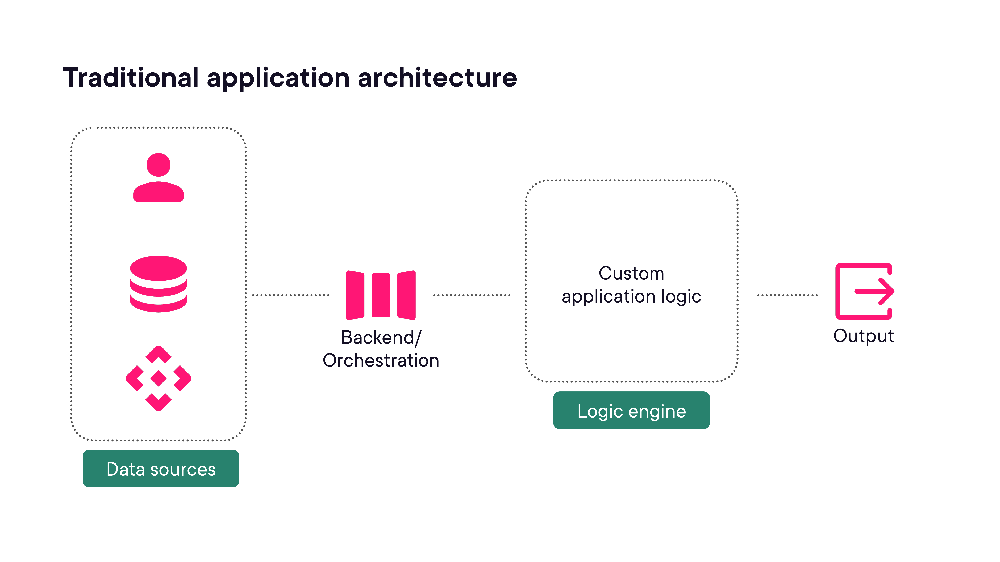

In [2]:
render_diagram(Path("assets/01-traditional-application-architecture.png"))

### AI-Native Application Architecture

An AI-native backend inserts a **reasoning layer** between input and business logic. Instead of hard-coded conditionals, an LLM classifies intent, infers missing fields, and produces structured output that the rest of the system consumes.

The new flow:

1. **Raw Input** (natural language, partial data)
2. **LLM Classification** — interprets intent and fills structure
3. **Schema Validation** — verifies the LLM's output is well-formed
4. **Intent Router** — dispatches to the correct handler
5. **Business Logic / Data Access**
6. **Response**

Validation moves from the entry point to the LLM boundary — because the dangerous, unpredictable input is now what the model returns.


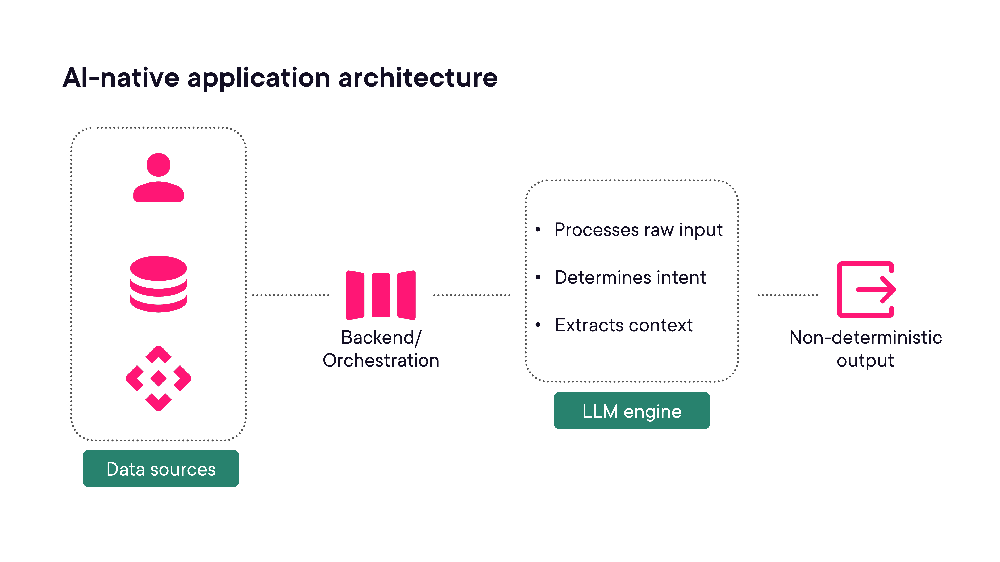

In [3]:
render_diagram(Path("assets/02-ai-native-application-architecture.png"))

### From Fixed Components to an Autonomous Agent

As AI-native systems mature, the reasoning layer grows from a single classification step into a full **agentic loop**: the system plans what to do, acts, observes what happened, and reflects on whether the outcome was correct — then decides whether to loop again or finalise a result.

This is the progression tracked across this course:

| Stage | What changes |
|---|---|
| Traditional | Fixed pipeline, no LLM |
| AI-assisted | LLM classifies; code routes |
| AI-native | LLM drives; code validates |
| Agentic | Loop: Plan → Act → Observe → Reflect |


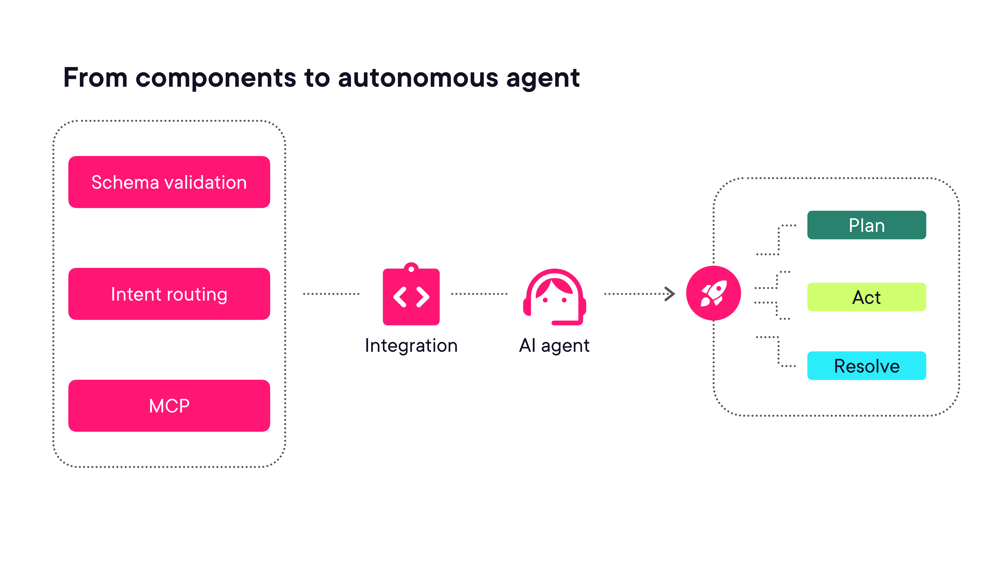

In [4]:
render_diagram(Path("assets/03-from-components-to-autonomous-agent.png"))

### What This Course Builds

**Supportflow AI** is a real Node.js / Express support-ticket backend that demonstrates every concept introduced in this course:

- **Zod schema validation** on both user input and LLM output
- **Intent-driven routing** — a `routeMap` that replaces if-else chains
- **MCP server** — exposes tickets as tools consumable by any MCP-compatible client
- **Agentic lifecycle** — Plan / Act / Observe / Reflect loop for complex ticket resolution

The demo project lives in [`supportflow-ai/`](supportflow-ai/).

### Supportflow AI — Full System Architecture

The architecture in this diagram is the north-star design for the entire course. Each module implements one layer of this system.


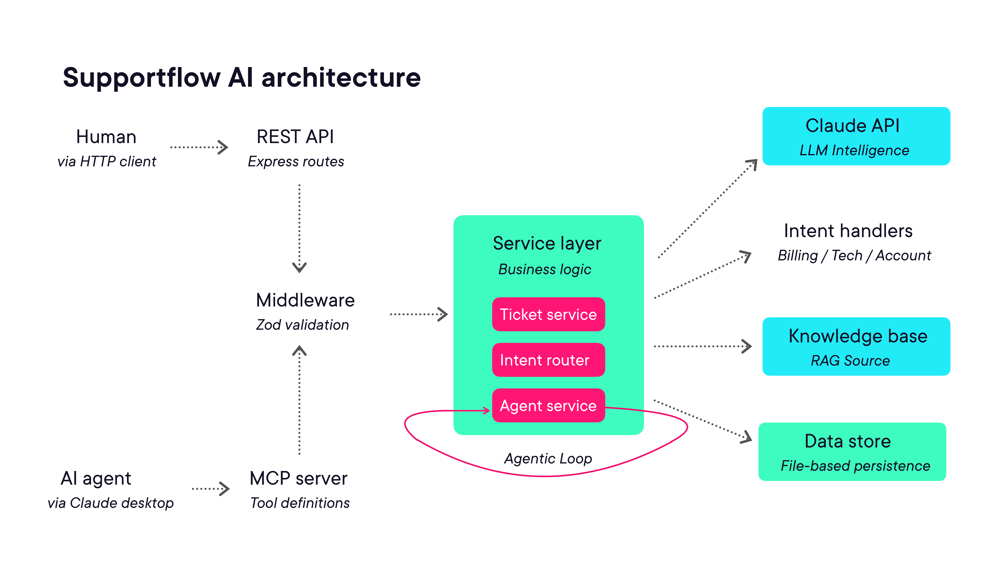

In [5]:
render_diagram(Path("assets/04-supportflow-ai-architecture.png"))

### Schema-First Validation: User Input Flow

For user-provided input (REST API body), schema validation is a **gate** at the network boundary:

- Define the expected shape with Zod
- Call `schema.safeParse(req.body)` in middleware before any business logic runs
- On failure → return `400` with structured error details
- On success → attach `req.validatedData` and call `next()`

Nothing downstream ever sees unvalidated data.


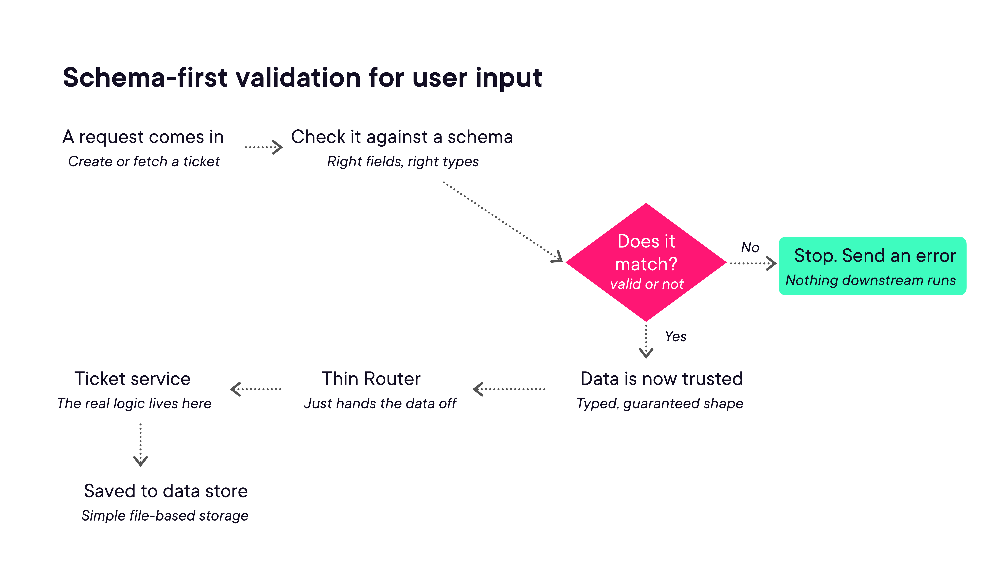

In [6]:
render_diagram(Path("assets/05-schema-first-validation-user-input-flow.png"))

### `parse` vs `safeParse`

Zod provides two validation entry points with very different error semantics:

| Method | On failure | Use when |
|---|---|---|
| `schema.parse(data)` | **throws** a `ZodError` | You want an exception to propagate up (trusted data, tests) |
| `schema.safeParse(data)` | returns `{ success: false, error }` | You want to inspect and return errors (API boundaries, middleware) |

**Rule:** In middleware and LLM-output validation, always use `safeParse` — you need the error object to generate a meaningful response or feedback prompt. Reserve `parse` for internal code where a schema failure is truly unexpected.


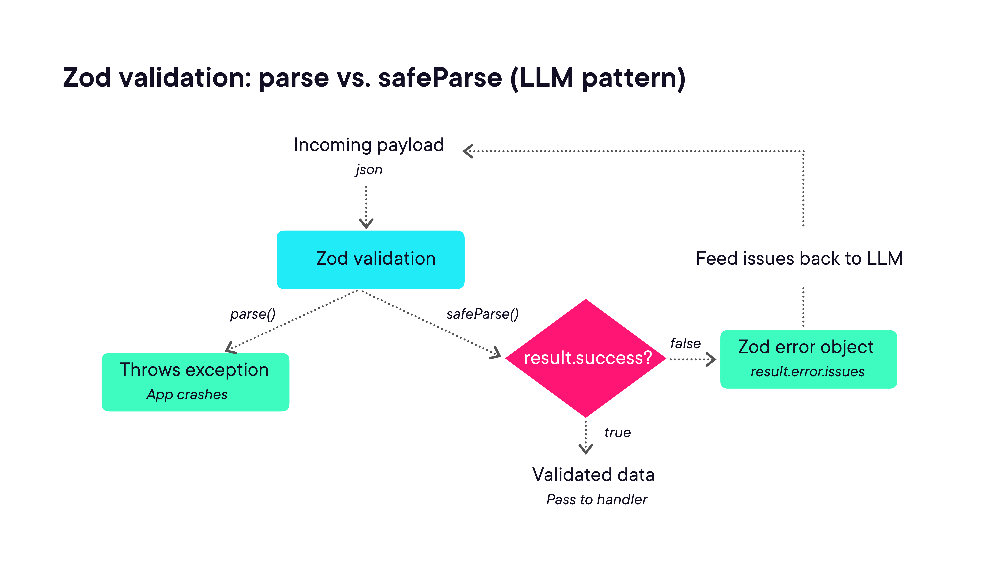

In [7]:
render_diagram(Path("assets/06-zod-parse-vs-safeParse-flow.png"))

### Zod Schema in Practice: `TicketRequestSchema`

The ticket schema is the single source of truth for what a valid ticket looks like across both the HTTP API and the LLM classification output:

```javascript
const { z } = require('zod');

const TicketRequestSchema = z.object({
    title: z.string().min(5).max(200),
    description: z.string().min(20).max(2000),
    customerEmail: z.email('Enter a valid email address'),
    category: z.enum(['BILLING', 'TECHNICAL', 'ACCOUNT', 'GENERAL']),
    priority: z.enum(['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']),
    referenceId: z.string().min(1).optional(),
});

// Saved tickets extend the request schema with server-generated fields
const SavedTicketSchema = TicketRequestSchema.extend({
    id: z.uuid(),
    status: z.enum(['OPEN', 'IN_PROGRESS', 'RESOLVED', 'CLOSED', 'ESCALATED', 'RESOLVED_SELF_SERVE']),
    createdAt: z.iso.datetime(),
});
```

Using `.extend()` for `SavedTicketSchema` means both schemas stay in sync — change `TicketRequestSchema` and `SavedTicketSchema` automatically inherits the update.

### Validation Middleware

```javascript
function validate(schema) {
    return (req, res, next) => {
        const result = schema.safeParse(req.body);

        if (!result.success) {
            return res.status(400).json({
                error: 'Validation failed',
                details: result.error.issues,
            });
        }

        req.validatedData = result.data;
        next();
    };
}
```

Usage in a route:
```javascript
router.post('/tickets', validate(TicketRequestSchema), createTicketHandler);
```

The middleware is schema-agnostic — pass any Zod schema and it returns a ready-to-use Express middleware function.

### Schema-First Validation: LLM Output Flow

When an LLM is involved, validation moves from the entry point to the **LLM boundary**. The LLM is asked to produce structured JSON; the schema validates whether it actually did.

If the LLM returns invalid output, the error messages are fed back to it as a correction prompt — giving it an opportunity to self-correct before the request fails.


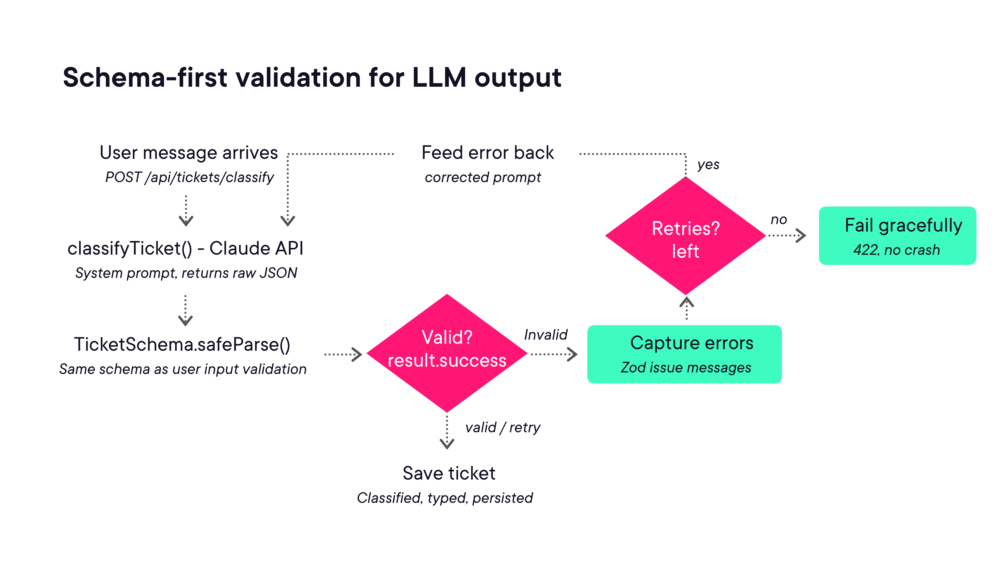

In [8]:
render_diagram(Path("assets/07-schema-first-validation-llm-output-flow.png"))

---

## Module 02: Schema-First Validation for LLM Output

Deepens the validation story by focusing on the LLM boundary specifically — why LLM output is structurally unreliable, how `safeParse` turns Zod errors into actionable correction prompts, and how the retry loop gives the model a chance to self-correct before failing the request.

### Why LLM Output Needs Schema Validation

Unlike user input — which can be rejected at the door — LLM output sits inside the system. If it's malformed, it propagates silently until something crashes.

Three failure modes to guard against:

1. **Network / API failure** — the Claude call fails entirely; `response` is null
2. **JSON parse failure** — the model returns text that isn't valid JSON (e.g. a Markdown code fence wrapping the JSON)
3. **Schema failure** — the JSON parses but violates the contract (wrong enum, missing required field, wrong type)

Each requires a different recovery strategy.

### The Three-Stage Validation Pipeline

```javascript
async function classifyTicket(messages) {
    // Stage 1: Network error
    let response;
    try {
        response = await anthropic.messages.create({ model: 'claude-sonnet-5', ... });
    } catch (error) {
        return { success: false, errors: [{ message: 'Claude API call failed', detail: error.message }], raw: null };
    }

    // Stage 2: JSON parse
    const rawText = response.content.find(b => b.type === 'text')?.text;
    const cleanedText = stripCodeFences(rawText);  // remove ```json ... ``` wrappers
    let parsedJson;
    try {
        parsedJson = JSON.parse(cleanedText);
    } catch (error) {
        return { success: false, errors: [{ message: 'LLM did not return valid JSON' }], raw: rawText };
    }

    // Stage 3: Schema validation
    const result = TicketRequestSchema.safeParse(parsedJson);
    if (!result.success) {
        return { success: false, errors: result.error.issues, raw: parsedJson };
    }

    return { success: true, data: result.data };
}
```

The `raw` field is key: when `raw: null` it signals a network error (retry without feedback); when `raw` contains the parsed JSON it signals a schema error (retry with Zod's error messages).

### Supportflow AI Architecture — Validation Layer Highlighted

In this module's context, the architecture diagram highlights the LLM classification + schema validation layer — specifically the feedback loop where Zod error messages are injected back into the conversation as correction prompts.


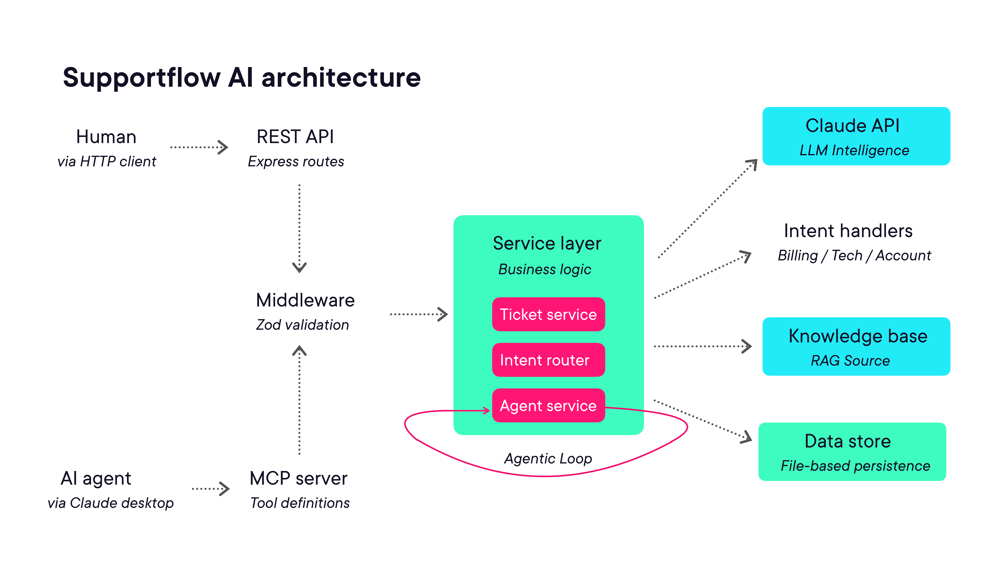

In [9]:
render_diagram(Path("assets/04-supportflow-ai-architecture.png"))

### The Retry Loop with Error Feedback

When the LLM returns invalid output, don't just retry blindly — feed the specific Zod error messages back as a correction prompt:

```javascript
const MAX_RETRIES = 3;

async function classifyTicketWithRetry(rawMessage) {
    const messages = [{ role: 'user', content: rawMessage }];

    for (let attempt = 1; attempt <= MAX_RETRIES; attempt++) {
        const result = await classifyTicket(messages);
        if (result.success) return { ...result, retriesUsed: attempt - 1 };

        if (attempt === MAX_RETRIES) return { ...result, retriesUsed: attempt - 1, exhausted: true };

        // Network error: retry same messages unchanged
        if (result.raw === null) continue;

        // Schema error: extend the conversation with the LLM's attempt + Zod feedback
        const errorFeedback = result.errors
            .map(e => `Field "${e.path?.join('.') || 'unknown'}": ${e.message}`)
            .join('\n');

        messages.push({ role: 'assistant', content: JSON.stringify(result.raw) });
        messages.push({
            role: 'user',
            content: `Your response had these validation errors:\n${errorFeedback}\n\nPlease fix only what's wrong.`
        });
    }
}
```

This conversational correction is far more reliable than simply re-sending the original prompt — the model sees exactly what it got wrong.

### Schema as a Contract Between Code and Model

The Zod schema is not just validation — it is the **contract** between the application and the LLM:

- The **system prompt** describes the contract in natural language ("classify this ticket into one of BILLING, TECHNICAL, ACCOUNT, GENERAL")
- The **Zod schema** enforces the contract in code (`z.enum(['BILLING', 'TECHNICAL', 'ACCOUNT', 'GENERAL'])`)
- **Zod error messages** translate enforcement failures back into natural language so the model can fix them

This bidirectional translation — schema ↔ human language — is what makes the retry loop effective.

### Lenient Schema for Missing Data

Sometimes the user's message genuinely doesn't contain a required field (e.g. no email address). Forcing the model to invent one produces hallucinations.

Solution: a **lenient variant** that accepts `null` for fields that can legitimately be absent:

```javascript
const TicketRequestSchemaLenient = TicketRequestSchema.extend({
    customerEmail: z.email('Enter a valid email address').nullable(),
});

const requireEmail = process.env.REQUIRE_CUSTOMER_EMAIL !== 'false';
const activeSchema = requireEmail ? TicketRequestSchema : TicketRequestSchemaLenient;
```

The correction prompt explicitly tells the model: _"If email is genuinely not in the message, return null for email — do not invent one."_

---

## Module 03: Intent-Driven Routing

Once the LLM has classified a ticket into a structured object, the system must decide what to do with it. This module replaces fragile if-else chains with a declarative `routeMap` pattern and applies the Open/Closed Principle to keep the router extensible without requiring changes to existing logic.

### The Problem: A Ticket with Missing Fields

Before routing can work, the ticket must be complete. The diagram below shows what the LLM might return when the user's message is vague — missing `priority` and `category` — and how the retry loop fills those gaps:


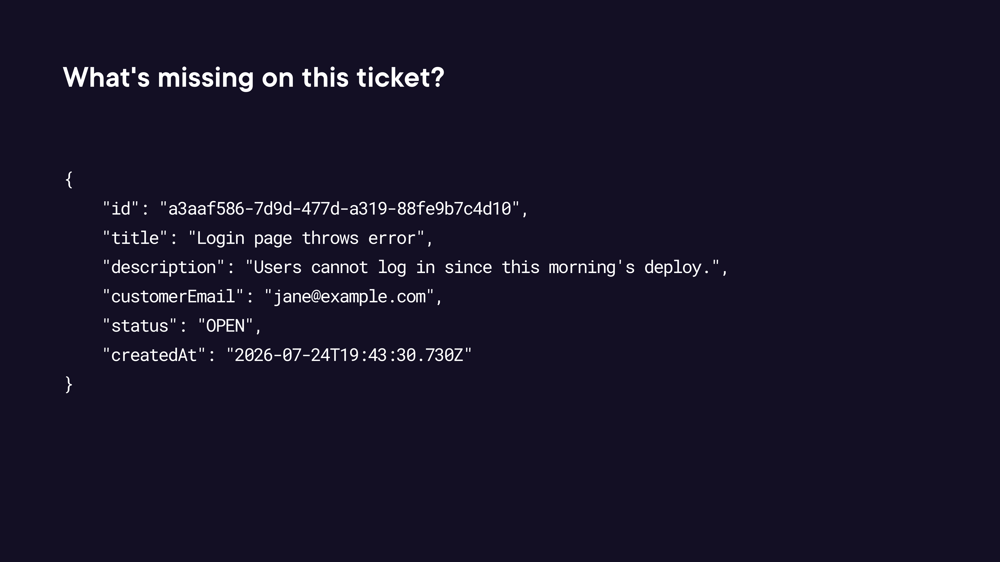

In [10]:
render_diagram(Path("assets/08-ticket-missing-fields.png"))

### Adding Priority

After the first correction turn, the model fills in `priority` — but `category` is still absent:


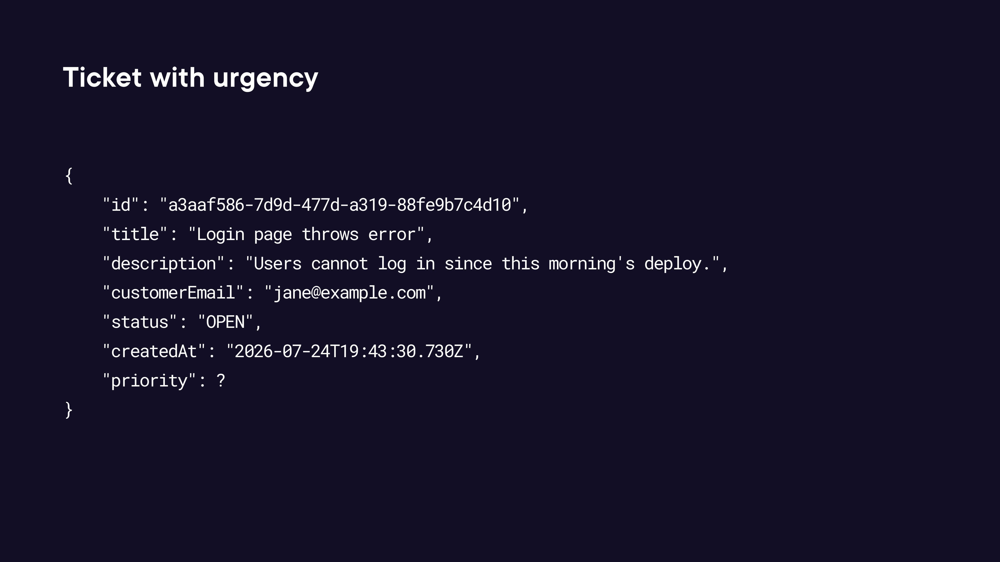

In [11]:
render_diagram(Path("assets/09-ticket-with-priority.png"))

### Complete Ticket: Priority and Category

After a second correction turn, the ticket is complete and ready to be routed:


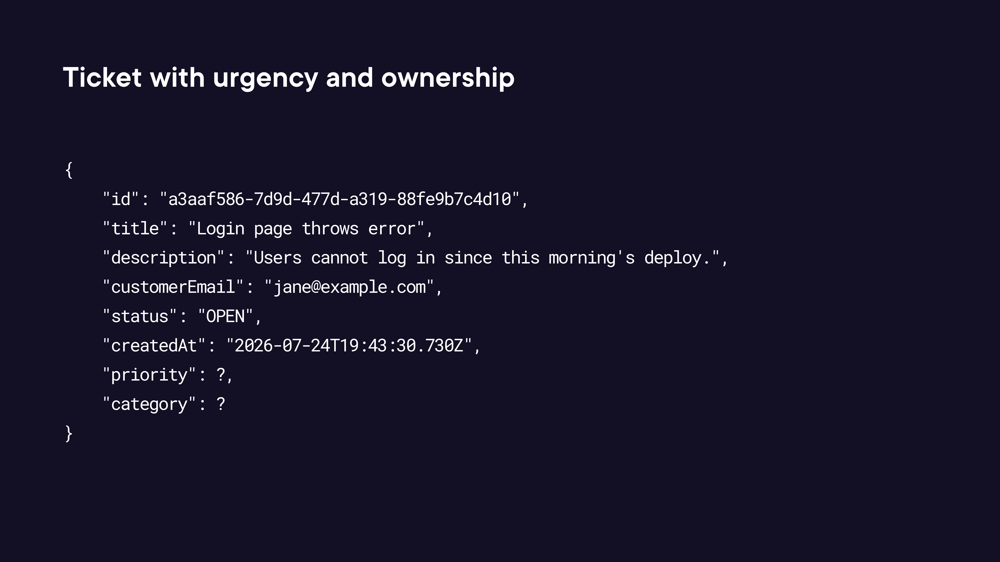

In [12]:
render_diagram(Path("assets/10-ticket-with-priority-and-category.png"))

### Routing with CRITICAL Priority Override

Routing is not purely category-based. A `CRITICAL` priority ticket always bypasses the category handler and goes directly to human escalation — regardless of category.

The diagram shows the two-path decision: CRITICAL → escalation, everything else → `routeMap` lookup:


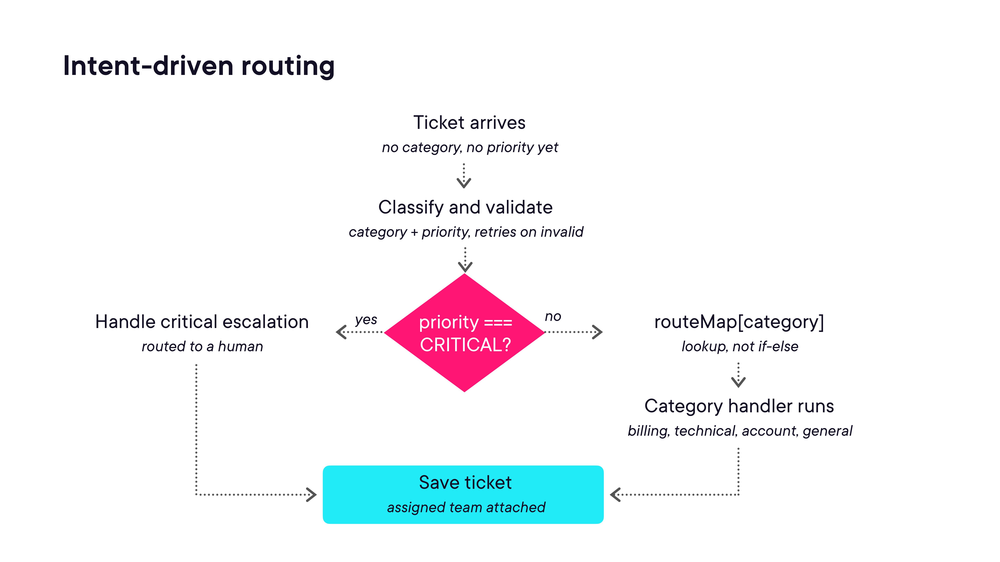

In [13]:
render_diagram(Path("assets/11-intent-driven-routing-with-critical.png"))

### Routing Without a CRITICAL Override

For non-critical tickets, routing is a pure category lookup:


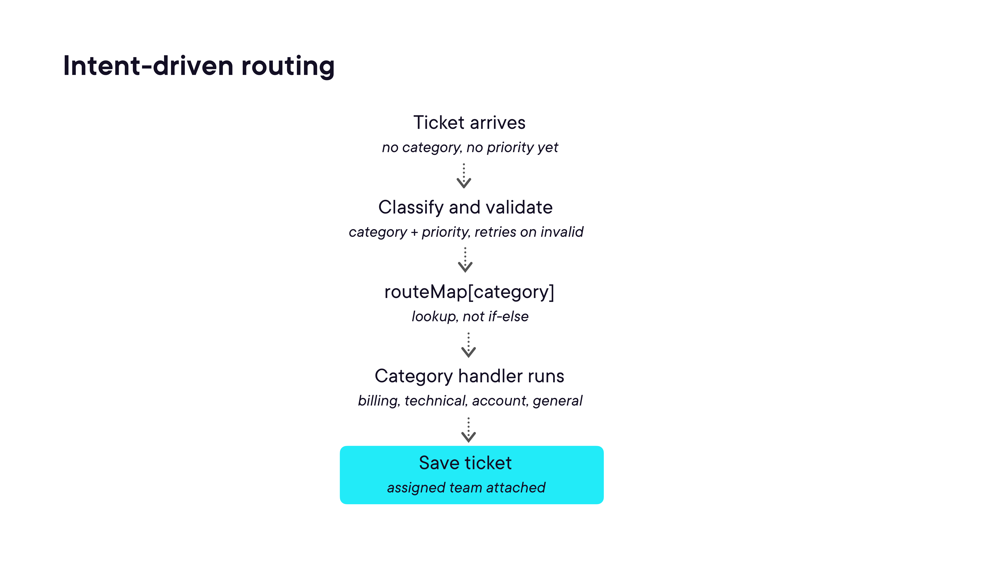

In [14]:
render_diagram(Path("assets/12-intent-driven-routing-no-critical.png"))

### The Problem with If-Else Chains

A naive routing implementation uses nested conditionals:

```javascript
if (ticket.priority === 'CRITICAL') {
    return handleCriticalEscalation(ticket);
} else if (ticket.category === 'BILLING') {
    return handleBillingTicket(ticket);
} else if (ticket.category === 'TECHNICAL') {
    return handleTechnicalTicket(ticket);
} else if (ticket.category === 'ACCOUNT') {
    return handleAccountTicket(ticket);
} else {
    return handleGeneralTicket(ticket);
}
```

Problems: O(n) lookup, every new category requires editing the router, and the priority check can easily get buried or duplicated.


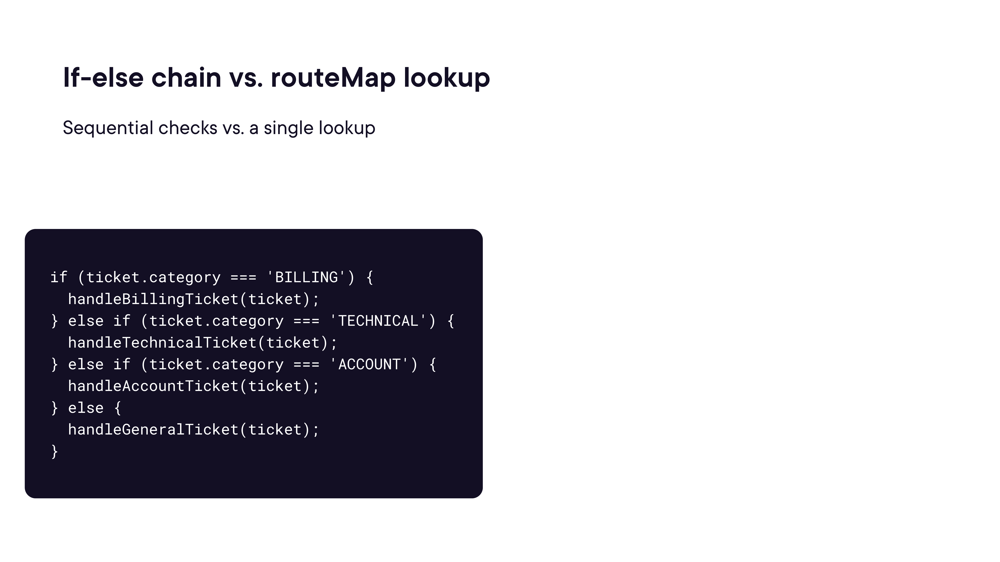

In [15]:
render_diagram(Path("assets/13-if-else-chain-only.png"))

### Replacing If-Else with a Route Map

A `routeMap` is a plain object where keys are category strings and values are handler functions:

```javascript
const routeMap = {
    BILLING:   handleBillingTicket,
    TECHNICAL: handleTechnicalTicket,
    ACCOUNT:   handleAccountTicket,
    GENERAL:   handleGeneralTicket,
};
```

Benefits:
- **O(1) lookup** — no chain to walk
- **Declarative** — the full routing table is visible at a glance
- **Extensible** — adding a category is a one-line map entry, not a new `else if`


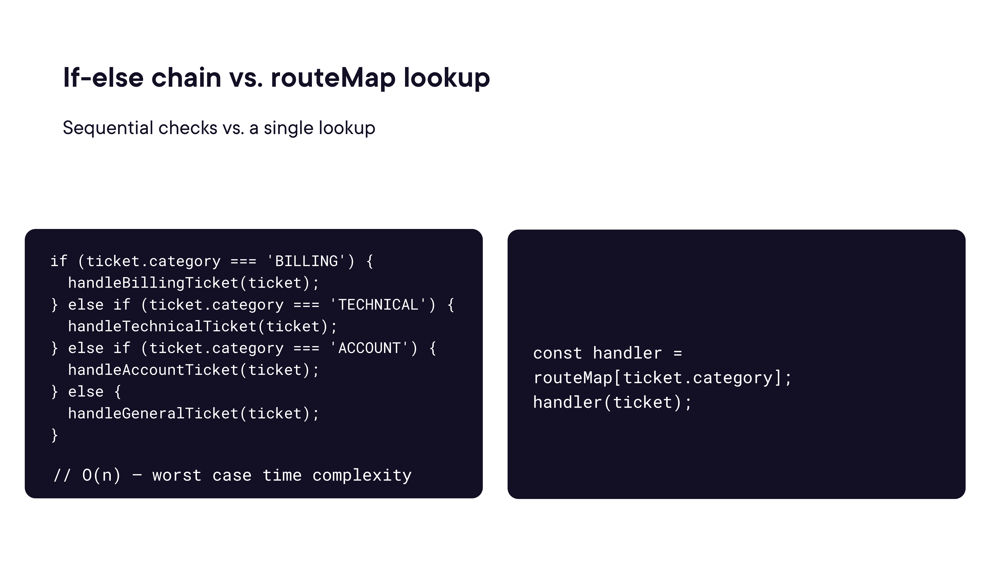

In [16]:
render_diagram(Path("assets/14-if-else-vs-routemap-with-handler.png"))


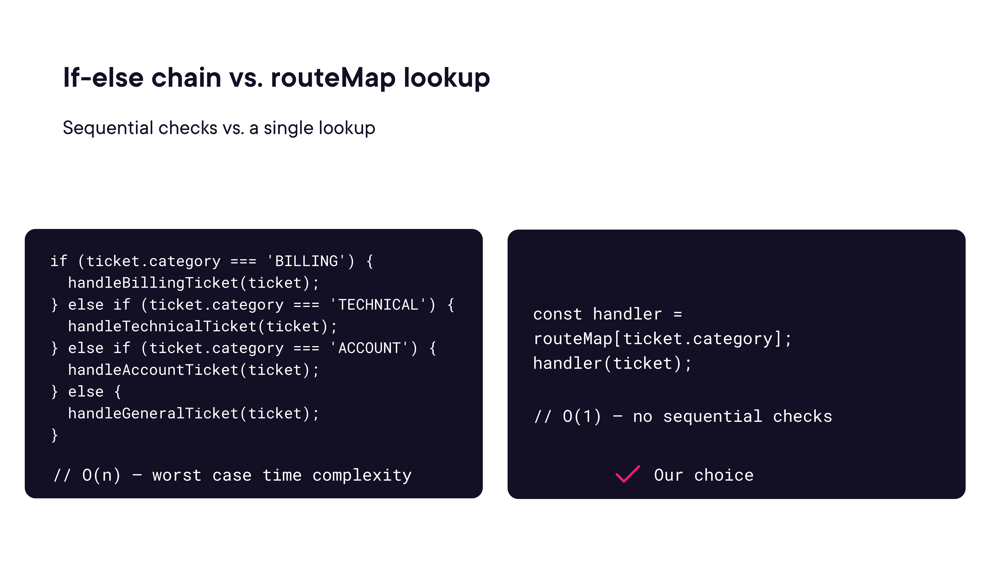

In [17]:
render_diagram(Path("assets/15-if-else-vs-routemap-final.png"))

### Open/Closed Principle

The **Open/Closed Principle** (OCP) states: software entities should be **open for extension** but **closed for modification**.

In the context of routing:

> The router function should never need to change when a new category is added.

The if-else version **violates OCP** — every new category requires modifying the router body. The `routeMap` version **satisfies OCP** — adding a new category only requires adding an entry to the map data structure.

Here is the router before applying OCP:


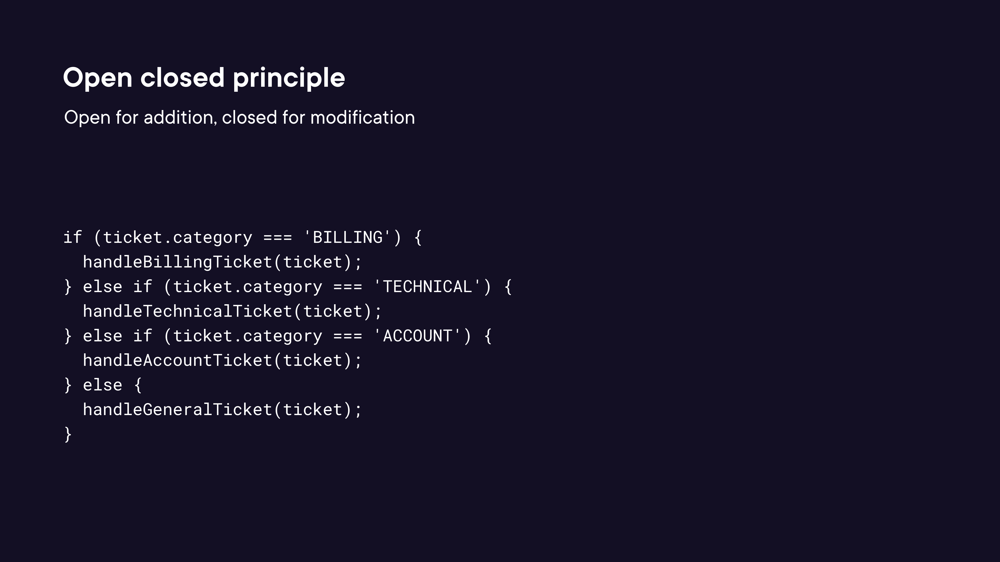

In [18]:
render_diagram(Path("assets/16-open-closed-original.png"))

### Open/Closed: Adding a Refunds Category

When we need to add a `REFUNDS` category to the if-else version, we have to open the router function and add another branch:


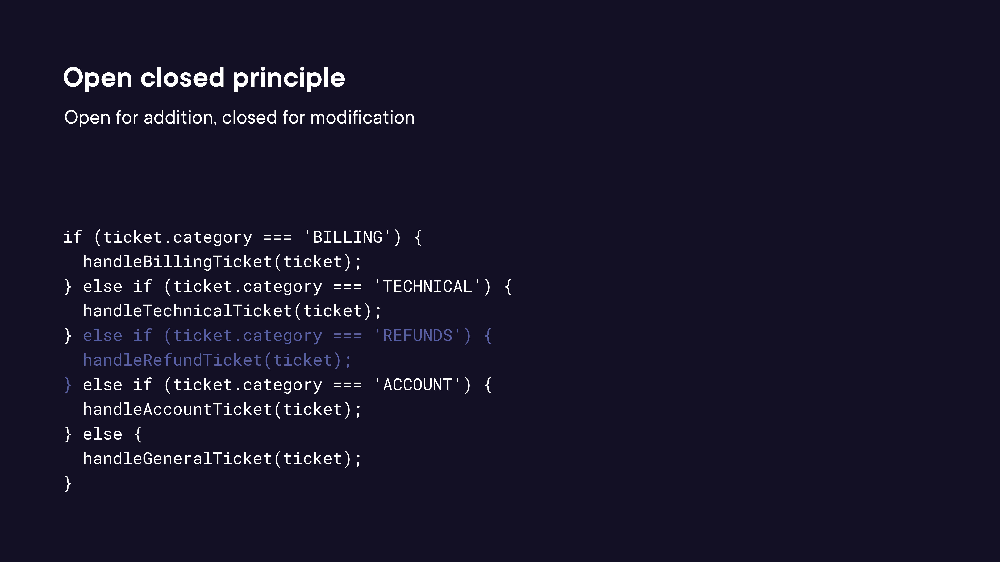

In [19]:
render_diagram(Path("assets/17-open-closed-with-refunds.png"))

### Open/Closed: Refunds with the routeMap

With the `routeMap` approach, adding `REFUNDS` is a single line in the map — the `routeTicket` function itself never changes:


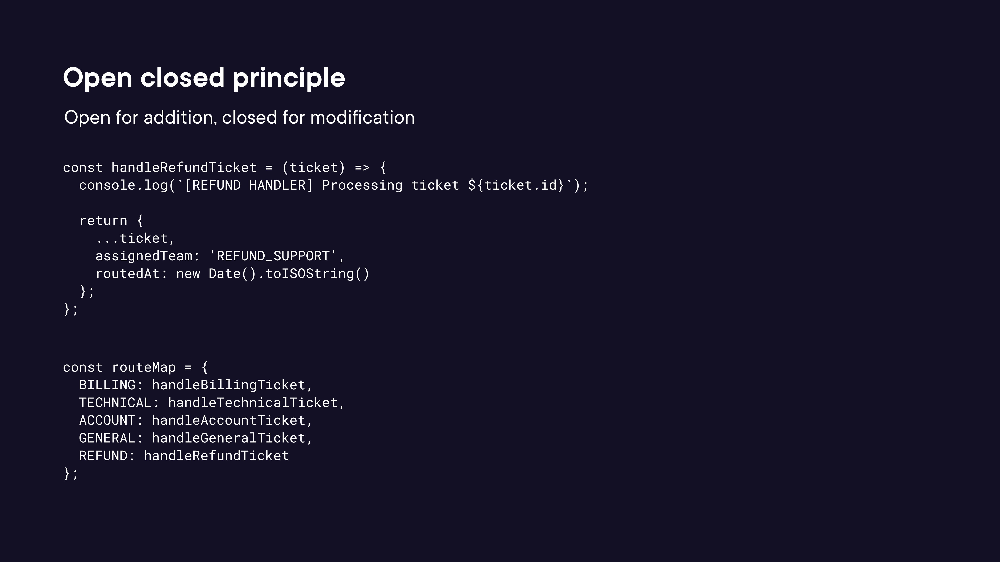

In [20]:
render_diagram(Path("assets/18-open-closed-routemap-refund.png"))

### Final Router Implementation

```javascript
const routeMap = {
    BILLING:   handleBillingTicket,
    TECHNICAL: handleTechnicalTicket,
    ACCOUNT:   handleAccountTicket,
    GENERAL:   handleGeneralTicket,
};

const routeTicket = (ticket) => {
    // CRITICAL priority always bypasses category routing
    if (ticket.priority === 'CRITICAL') {
        return handleCriticalEscalation(ticket);
    }

    const handler = routeMap[ticket.category];
    if (!handler) return handleGeneralTicket(ticket);  // safe fallback

    return handler(ticket);
};
```

The `CRITICAL` check remains as an explicit guard before the map lookup — because it's a priority override that cuts across all categories, not a category itself.

---

## Module 04: Model Context Protocol (MCP)

The Model Context Protocol (MCP) is an open standard for exposing backend capabilities as structured tools that LLM clients can discover and invoke. This module shows how to turn Supportflow AI's ticket operations into an MCP server using Node.js and the `@modelcontextprotocol/sdk` package.

### Before MCP: Tight Coupling

Without MCP, every AI client that wants to interact with Supportflow AI must know the exact HTTP API shape — endpoints, auth headers, request/response formats. Adding a new client means writing new integration code.


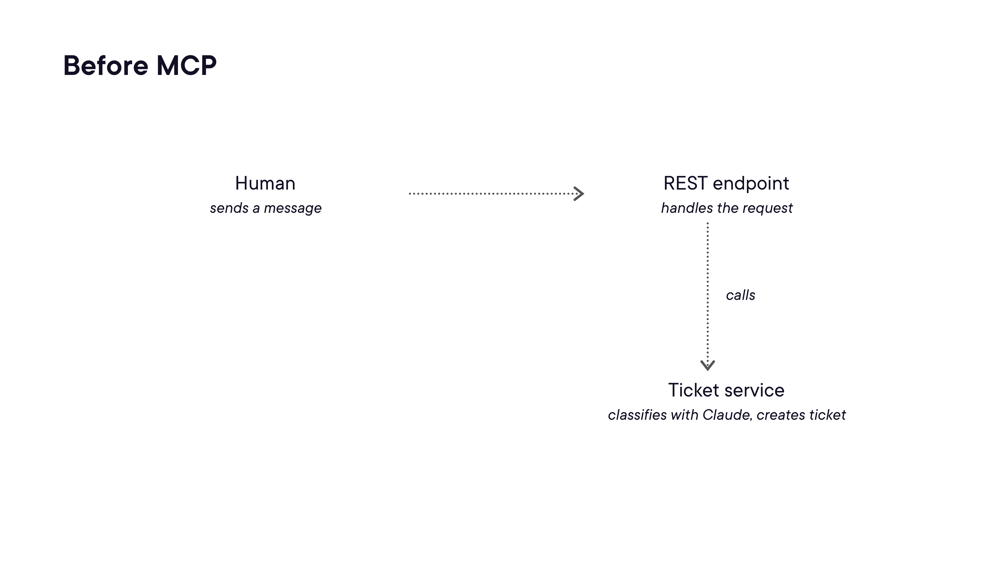

In [21]:
render_diagram(Path("assets/19-before-mcp-flow.png"))

### With MCP: Standardised Tool Discovery

With an MCP server in front of the backend, any MCP-compatible client (Claude Desktop, Cursor, a custom AI agent) can automatically discover available tools and invoke them without custom integration code.


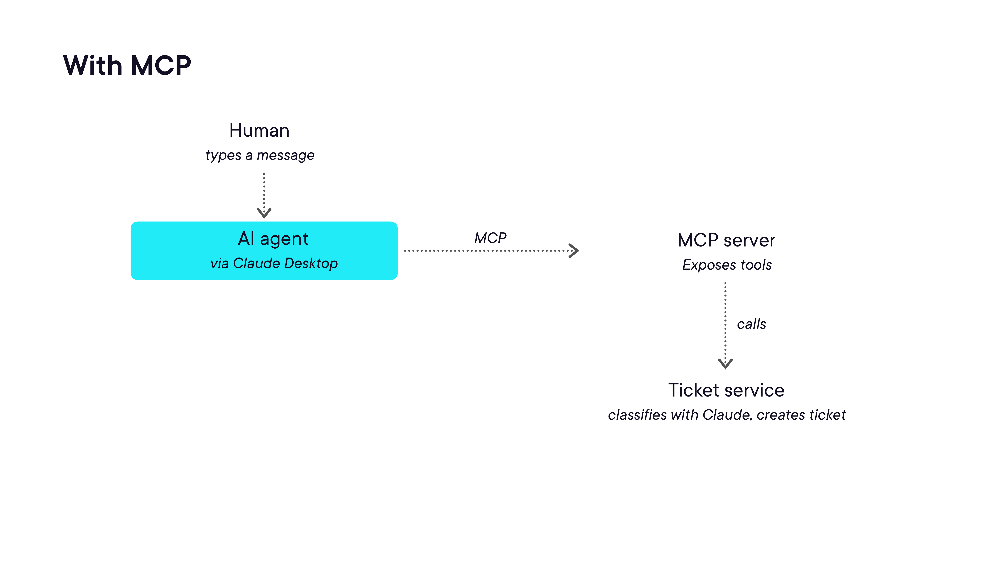

In [22]:
render_diagram(Path("assets/20-with-mcp-flow.png"))

### MCP Technical Flow

The protocol flow between an MCP client and server:

1. Client sends `tools/list` → server responds with available tools and their input schemas
2. Client sends `tools/call` with tool name + arguments → server executes and responds
3. All messages are JSON-RPC 2.0 over a transport (stdio, HTTP+SSE, or WebSocket)


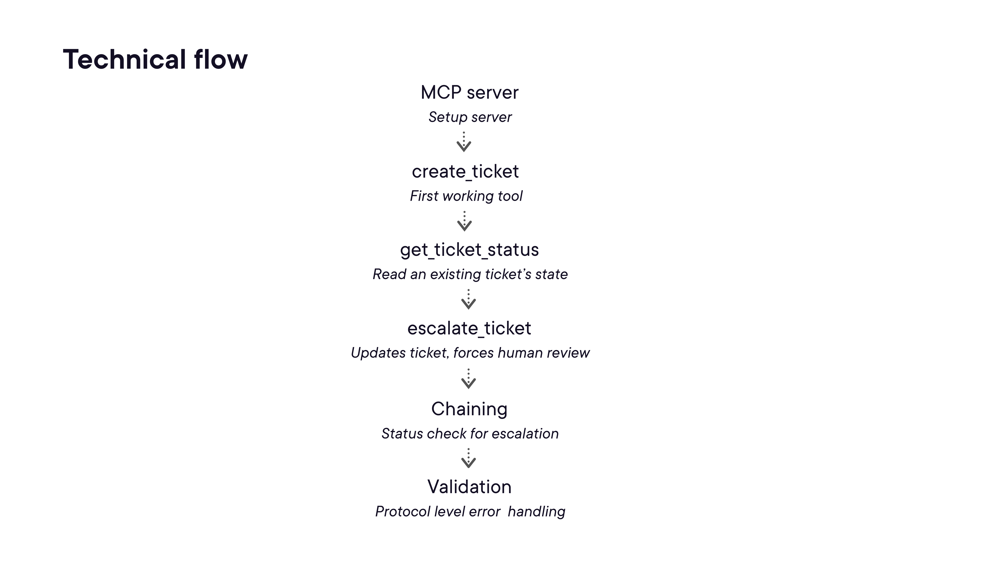

In [23]:
render_diagram(Path("assets/21-mcp-technical-flow.png"))

### Two Channels: stdout and stderr

In stdio transport, MCP uses a strict channel separation:

| Channel | Purpose |
|---|---|
| **stdout** | JSON-RPC protocol messages only — `tools/list` responses, `tools/call` responses |
| **stderr** | Logging, debug output, non-protocol text |

Any non-JSON written to stdout will corrupt the protocol stream and break the client connection. This means `console.log()` (which writes to stdout) must be replaced with `console.error()` (stderr) inside MCP server code.


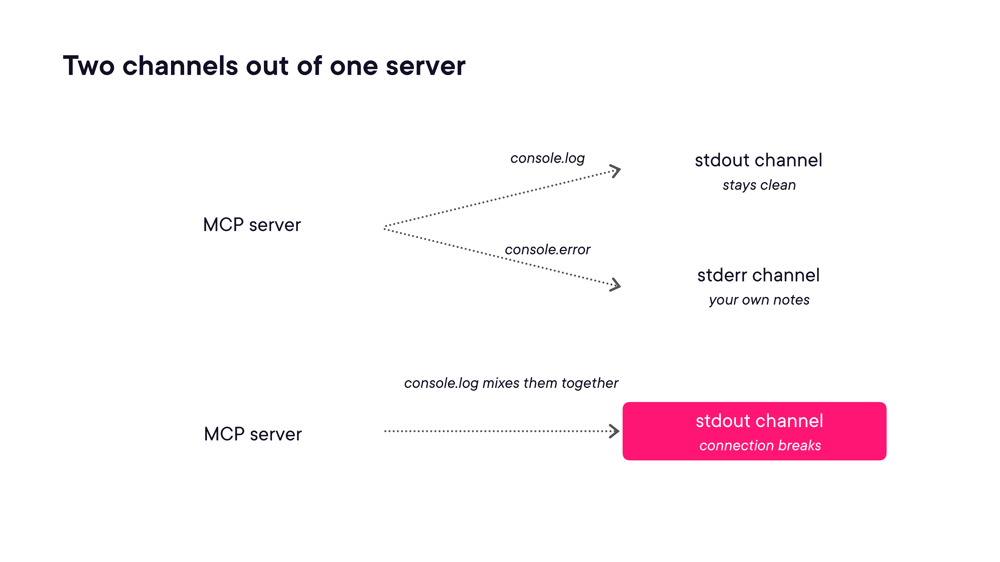

In [24]:
render_diagram(Path("assets/22-two-channels-stdout-stderr.png"))

### Why the `.js` Extension Matters in MCP Config

When Claude Desktop (or any MCP client) launches an MCP server via `node`, the entry point must be specified with an explicit `.js` extension in the config. Node.js module resolution depends on this — omitting the extension can cause the server to fail to start silently.


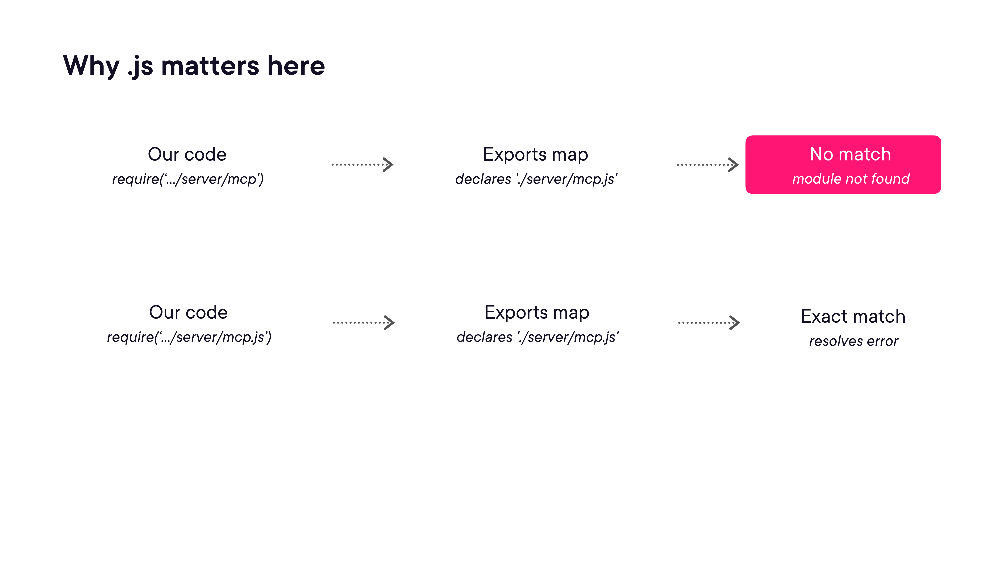

In [25]:
render_diagram(Path("assets/23-why-js-extension-matters.png"))

### Supportflow AI Architecture — MCP Layer Highlighted

In this module's context, the architecture diagram highlights the MCP server sitting alongside the REST API — sharing the same business logic but exposing it through a different protocol:


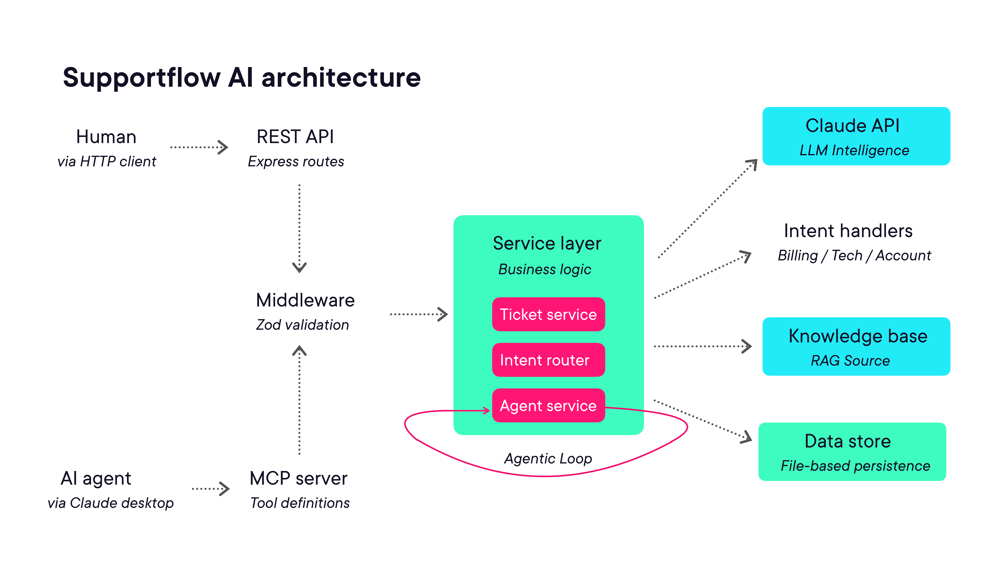

In [26]:
render_diagram(Path("assets/04-supportflow-ai-architecture.png"))

### MCP Server Implementation

```javascript
const { McpServer } = require('@modelcontextprotocol/sdk/server/mcp.js');
const { StdioServerTransport } = require('@modelcontextprotocol/sdk/server/stdio.js');

const server = new McpServer({
    name: 'supportflow-ai',
    version: '1.0.0'
});

server.registerTool(
    'create_ticket',
    {
        title: 'Create Support Ticket',
        description: 'Creates a support ticket from a natural language description of the issue',
        inputSchema: {
            message: z.string().describe("The user's issue described in plain English")
        }
    },
    async ({ message }) => {
        const result = await llmService.classifyTicketWithRetry(message);
        if (!result.success) {
            return { content: [{ type: 'text', text: `Could not classify ticket` }], isError: true };
        }
        const ticket = await ticketService.createTicketFromMessage(result.data);
        return { content: [{ type: 'text', text: `Ticket created: ${ticket.id}` }] };
    }
);

const transport = new StdioServerTransport();
await server.connect(transport);
```

Notice: the tool uses the same `classifyTicketWithRetry` service that the REST API uses — the MCP layer is just a different interface to the same logic.

### Two Entry Points, One Backend

The same backend serves both entry points:

- `server.js` — Express REST API (human callers, direct HTTP)
- `src/mcp/mcp-server.js` — MCP stdio server (AI clients, Claude Desktop)

Both share the same services (`llm.service.js`, `ticket.service.js`, `intent-router.service.js`). The entry point only changes the transport layer.


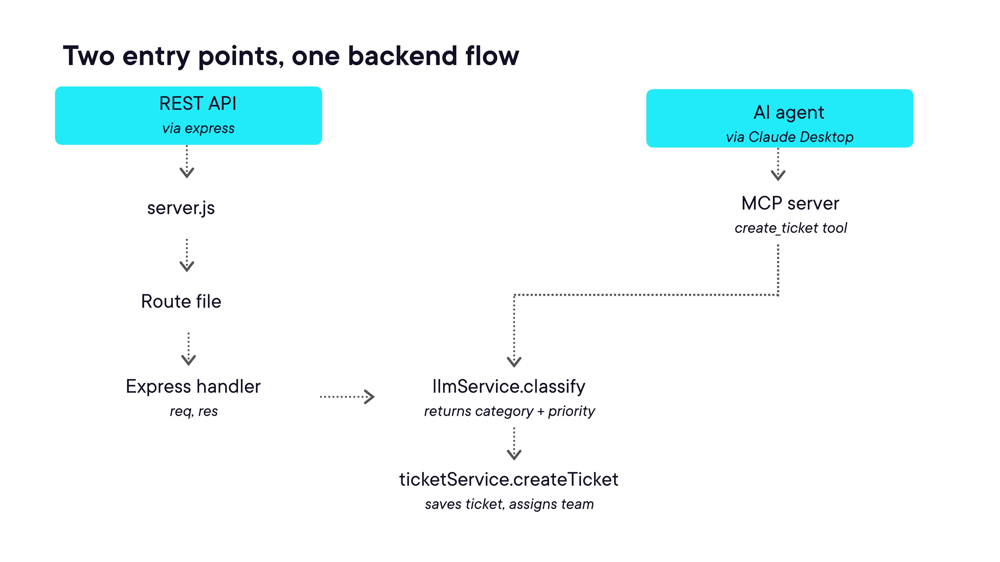

In [27]:
render_diagram(Path("assets/24-two-entry-points-one-backend.png"))

### Eager vs. On-Demand Tool Execution

Two approaches to ticket creation via MCP:

| Pattern | Description | Trade-off |
|---|---|---|
| **Eager (at creation)** | `create_ticket` classifies, validates, routes, and resolves the ticket in one call | Simple for the caller; slower tool call response |
| **On-demand** | `create_ticket` creates the ticket; the caller uses `resolve_ticket` separately | More composable; requires the caller to orchestrate two calls |

Supportflow AI uses the eager approach — the `create_ticket` tool does full classification + routing in one invocation.


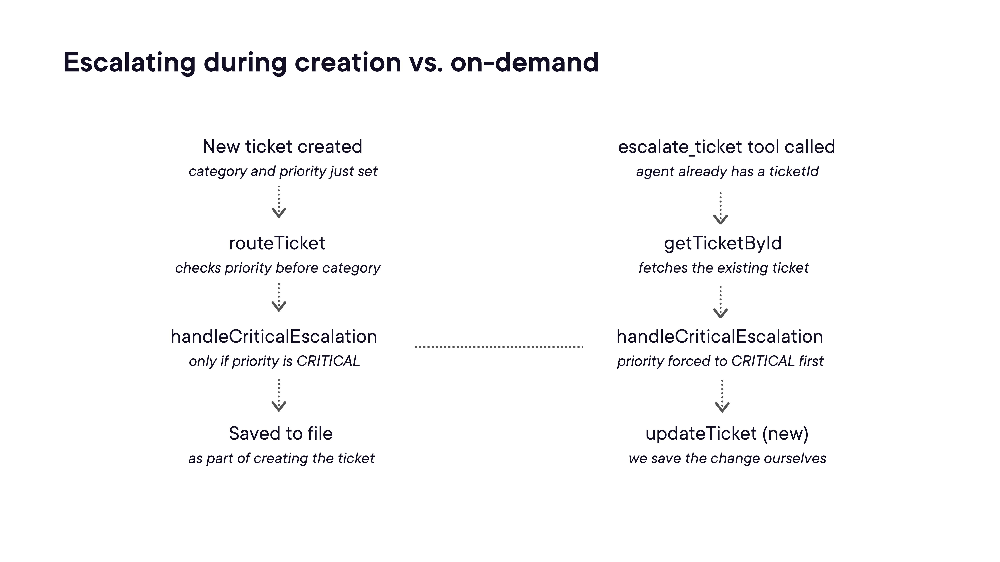

In [28]:
render_diagram(Path("assets/25-escalating-creation-vs-ondemand.png"))

---

## Module 05: The Agentic Lifecycle Pattern

For complex tickets that require reasoning — checking a knowledge base, verifying a claim, deciding whether to auto-resolve or escalate — a simple classify-and-route pipeline isn't enough. This module implements the **Plan → Act → Observe → Reflect** agentic loop that gives the system real autonomous decision-making.

### Same Flow, One New Step

The agentic pattern extends the existing flow rather than replacing it. After routing, instead of immediately returning a handler result, the system enters the agentic loop:


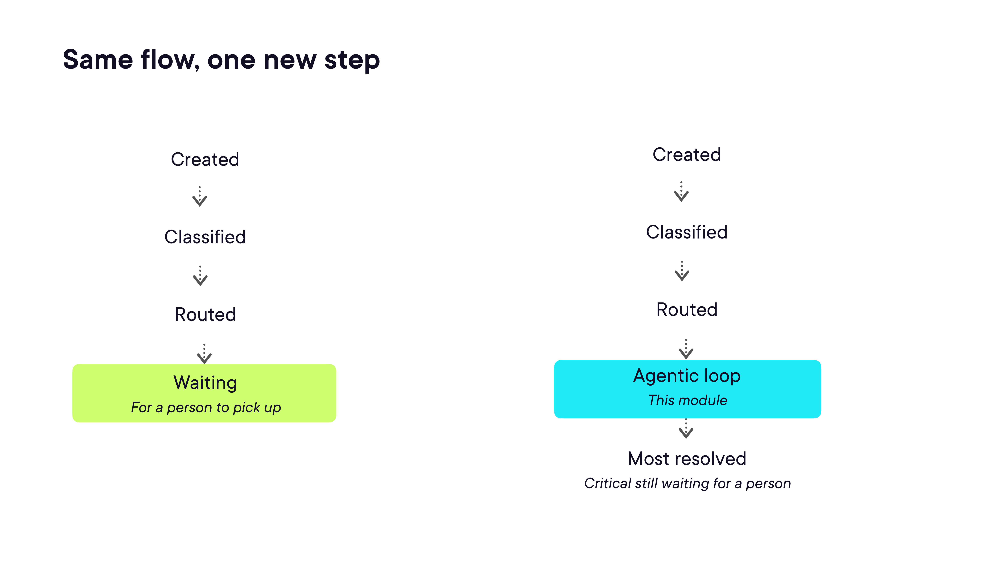

In [29]:
render_diagram(Path("assets/26-same-flow-one-new-step.png"))

### Two Paths, One Outcome

The agentic loop resolves to one of two outcomes regardless of path:

- **Self-serve resolution** — the system answered the question from the knowledge base or LLM, no human needed
- **Escalation** — the system could not verify a claim or the ticket requires human judgment

Both outcomes update the ticket status and return a response message to the caller.


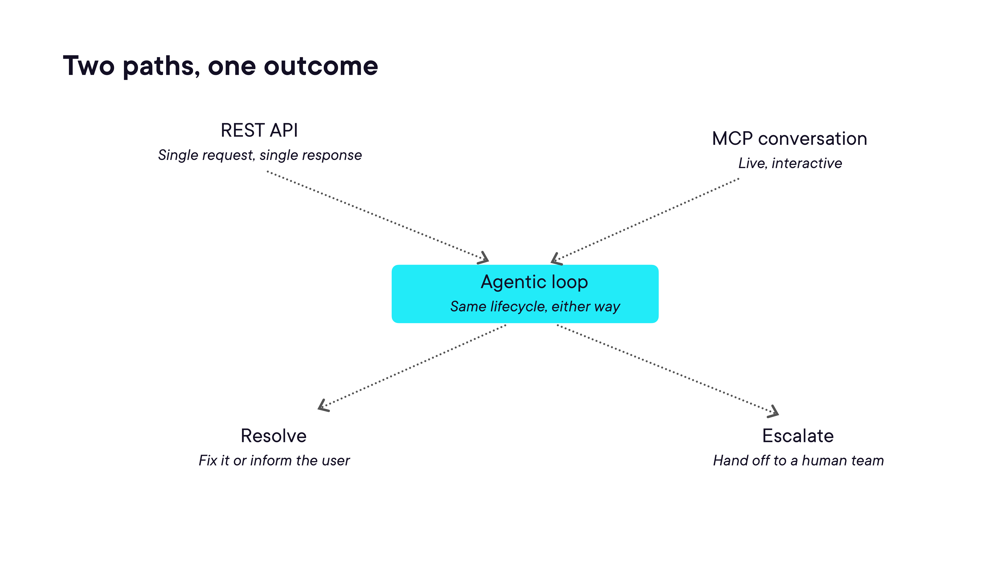

In [30]:
render_diagram(Path("assets/27-two-paths-one-outcome.png"))

### Supportflow AI Architecture — Agentic Layer Highlighted

In this module's context, the architecture diagram highlights the agentic services layer (Plan / Act / Observe / Reflect) and how it connects to the knowledge base and the LLM fallback:


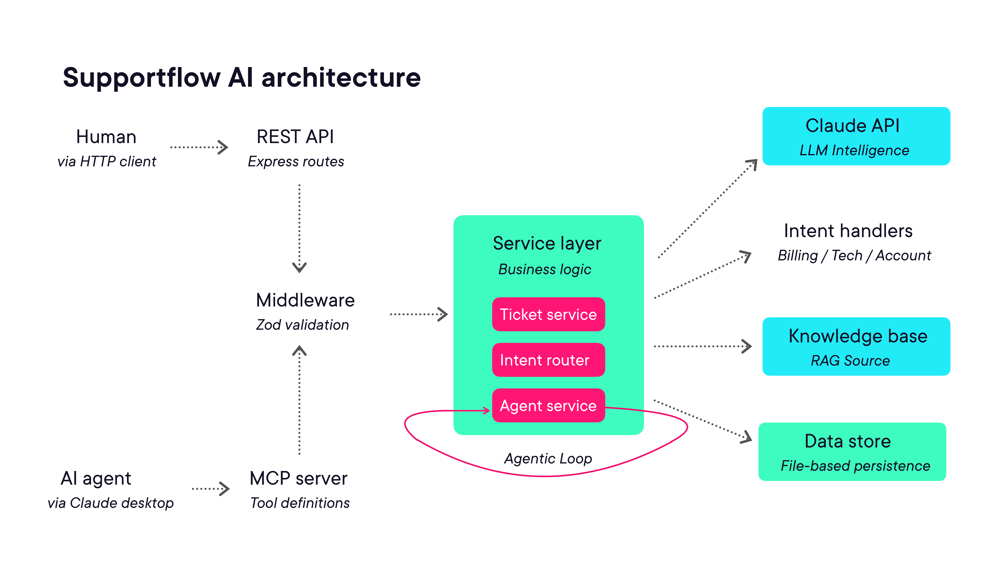

In [31]:
render_diagram(Path("assets/04-supportflow-ai-architecture.png"))

### The Agentic Lifecycle: Plan → Act → Observe → Reflect

Each phase has a single, well-defined responsibility:

| Phase | Service | What it does |
|---|---|---|
| **Plan** | `plan.service.js` | Searches the knowledge base for a matching solution; falls back to LLM if none found |
| **Act** | `act.service.js` | Executes the plan — validates claims, applies fixes, or calls the LLM for a direct answer |
| **Observe** | `observe.service.js` | Checks whether the action succeeded; flags discrepancies (e.g. claim couldn't be verified) |
| **Reflect** | `reflect.service.js` | Makes the final decision: RESOLVED, ESCALATED, or RESOLVED_SELF_SERVE; updates ticket status |

### Plan: Knowledge Base First

```javascript
function planTicket(ticket) {
    const query = `${ticket.title} ${ticket.description}`;
    const kbMatch = searchKnowledgeBase(query);

    if (kbMatch) {
        return { source: 'KNOWLEDGE_BASE', actionType: kbMatch.actionType, kbEntry: kbMatch };
    }

    return { source: 'LLM_FALLBACK', actionType: 'PROVIDE_INFO', kbEntry: null };
}
```

The knowledge base is checked first — deterministic, fast, no API cost. LLM is the fallback for queries the KB doesn't cover.

### Act: Validate Claims Before Applying Fixes

```javascript
async function performAction(plan, ticket) {
    if (plan.actionType === 'FIX_ISSUE' && plan.source === 'KNOWLEDGE_BASE') {
        const isValid = validateClaim(ticket);  // checks referenceId against business records

        if (isValid) {
            return { actionType: 'FIX_ISSUE', executed: true, resultMessage: plan.kbEntry.solution };
        }
        // Claim couldn't be verified — don't apply the fix
        return { actionType: 'FIX_ISSUE', executed: false, resultMessage: null };
    }

    // PROVIDE_INFO path: KB or LLM answer
    if (plan.source === 'KNOWLEDGE_BASE') {
        return { actionType: 'PROVIDE_INFO', executed: false, source: 'KNOWLEDGE_BASE',
                 resultMessage: plan.kbEntry.solution };
    }

    const llmAnswer = await askLLMDirectly(ticket);
    return { actionType: 'PROVIDE_INFO', executed: false, source: 'LLM', resultMessage: llmAnswer };
}
```

The `executed: false` flag for `FIX_ISSUE` is the signal that the Observe phase picks up — it means a claim fix was attempted but not applied.

### Where CRITICAL Tickets Go

CRITICAL priority tickets skip the agentic loop entirely — they go directly to escalation. The diagram shows this bypass path:


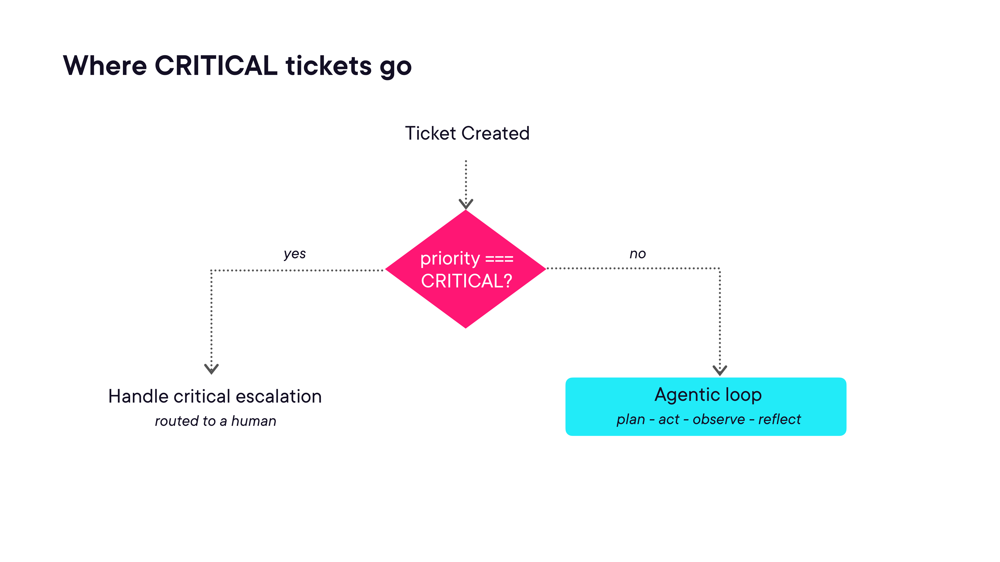

In [32]:
render_diagram(Path("assets/28-where-critical-tickets-go.png"))

### Observe: Surface Discrepancies

```javascript
function observeResult(actionResult, ticket) {
    const observed = {
        actionType: actionResult.actionType,
        executed: actionResult.executed,
        resultMessage: actionResult.resultMessage,
        observedAt: new Date().toISOString(),
    };

    // Discrepancy: a fix was planned but the claim couldn't be verified
    if (actionResult.actionType === 'FIX_ISSUE' && !actionResult.executed) {
        observed.discrepancy = true;
        observed.investigationNote = ticket.referenceId
            ? `Customer provided reference ID "${ticket.referenceId}", but the claim could not be verified.`
            : `Customer requested a fix, but provided no reference ID.`;
    }

    return observed;
}
```

The observation layer is read-only — it adds metadata about what happened without changing anything.

### Who Decides What's Safe?

A key design question in agentic systems: should the LLM decide whether an action is safe to execute? The answer in Supportflow AI is **no** — the LLM's job is to _inform_, not to _authorise_.

The `validateClaim` function in `act.service.js` checks against real business records (payment logs, order history). The LLM classification only determines _what_ the ticket is asking for — the code decides _whether_ to do it.


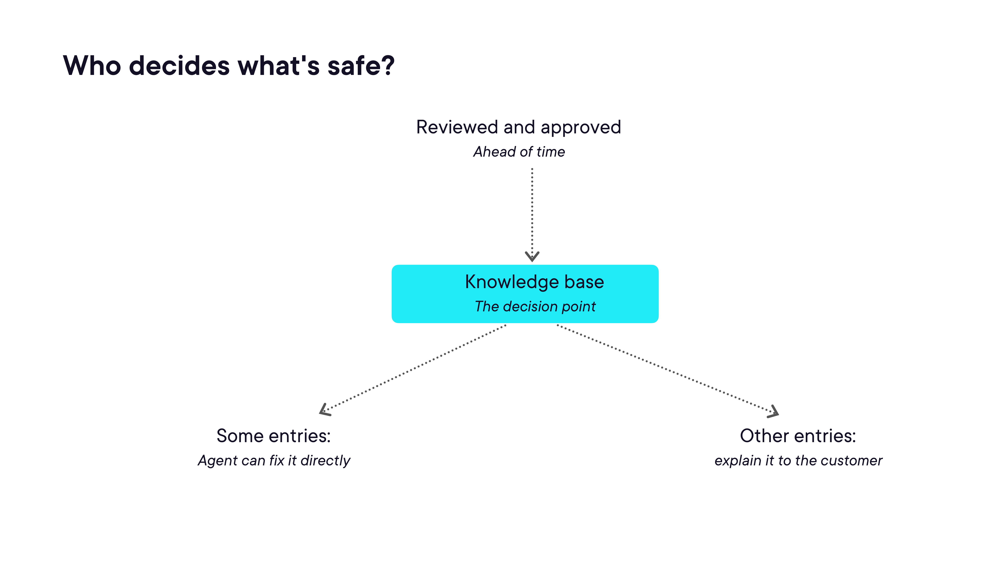

In [33]:
render_diagram(Path("assets/29-who-decides-whats-safe.png"))

### The LLM's One Job: Inform

The architectural boundary is clear: the LLM produces information; code acts on it. The LLM never directly mutates state, never authorises a transaction, and never decides whether a claim is valid. Those decisions belong to deterministic, auditable code.


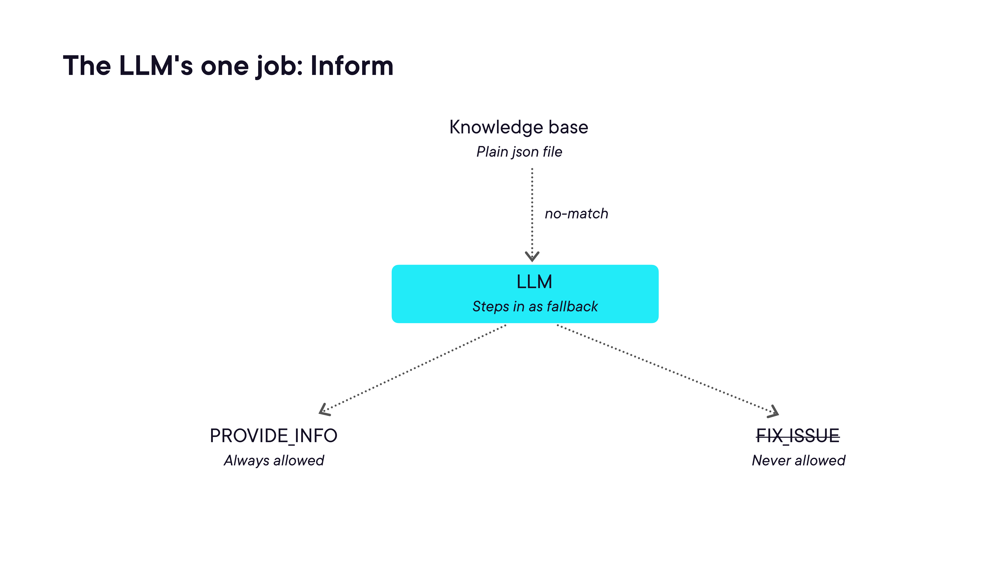

In [34]:
render_diagram(Path("assets/30-llm-one-job-inform.png"))

### Reflect: Make the Final Decision

```javascript
function reflectOnResult(ticket, observed) {
    // A fix was applied successfully
    if (observed.actionType === 'FIX_ISSUE' && observed.executed) {
        return { outcome: 'RESOLVED', ticket: updateTicket(ticket.id, { status: 'RESOLVED' }),
                 responseMessage: observed.resultMessage };
    }

    // A fix was planned but the claim failed verification → escalate with context
    if (observed.actionType === 'FIX_ISSUE' && !observed.executed) {
        return { outcome: 'ESCALATED',
                 ticket: updateTicket(ticket.id, { status: 'ESCALATED',
                     escalationNote: observed.investigationNote }),
                 responseMessage: `We escalated this to our support team with our findings.` };
    }

    // Information provided (KB or LLM) → self-serve resolved
    return { outcome: 'RESOLVED_SELF_SERVE',
             ticket: updateTicket(ticket.id, { status: 'RESOLVED_SELF_SERVE' }),
             responseMessage: `${observed.resultMessage}\n\nIf this doesn't resolve your issue, let us know.` };
}
```

Reflect is the only phase that writes to the database (`updateTicket`). Every prior phase is read-only or in-memory. This containment makes the loop easy to reason about and test.

### Composing the Loop

```javascript
async function resolveTicket(ticket) {
    const plan     = planTicket(ticket);
    const action   = await performAction(plan, ticket);
    const observed = observeResult(action, ticket);
    const result   = reflectOnResult(ticket, observed);
    return result;
}
```

The orchestrator in `agent.service.js` is deliberately thin — it just chains the four phases. All logic lives in the individual service functions, making each phase independently testable.

---

## Demo Project: Supportflow AI

The complete source is in [`supportflow-ai/`](supportflow-ai/). Below is an orientation to the project structure and how to run it.

### Project Structure

```
supportflow-ai/
├── server.js                          # Express REST API entry point
├── src/
│   ├── schemas/
│   │   └── ticket.schema.js           # Zod schemas: TicketRequestSchema, SavedTicketSchema
│   ├── middleware/
│   │   └── validate.middleware.js     # validate(schema) factory for Express routes
│   ├── services/
│   │   ├── llm.service.js             # classifyTicketWithRetry — 3-attempt retry with Zod feedback
│   │   ├── intent-router.service.js   # routeMap + routeTicket with CRITICAL bypass
│   │   ├── agent.service.js           # resolveTicket — orchestrates the agentic loop
│   │   ├── plan.service.js            # planTicket — KB search + LLM fallback
│   │   ├── act.service.js             # performAction — claim validation, fixes, LLM answers
│   │   ├── observe.service.js         # observeResult — discrepancy detection
│   │   ├── reflect.service.js         # reflectOnResult — final status update
│   │   ├── ticket.service.js          # CRUD for tickets (in-memory store)
│   │   └── knowledge-base.service.js  # KB search (keyword matching)
│   ├── handlers/
│   │   └── category.handler.js        # Per-category and escalation handlers
│   ├── prompts/
│   │   ├── classify-ticket.prompt.js  # SYSTEM_PROMPT for ticket classification
│   │   └── agent-fallback.prompt.js   # FALLBACK_SYSTEM_PROMPT for direct LLM answers
│   ├── utils/
│   │   └── strip-code-fences.util.js  # Strips ```json ... ``` wrappers from LLM output
│   └── mcp/
│       └── mcp-server.js              # MCP stdio server with create_ticket, get_ticket_status, escalate_ticket
├── scripts/
│   ├── test-act.js
│   ├── test-knowledge-base.js
│   ├── test-reflect.js
│   └── test-observe.js
└── package.json
```

### Setup

```bash
cd supportflow-ai
npm install
cp .env.example .env  # add ANTHROPIC_API_KEY
```

**Dependencies:**

| Package | Version | Purpose |
|---|---|---|
| `@anthropic-ai/sdk` | `^0.115.0` | Claude API client |
| `@modelcontextprotocol/sdk` | `^1.30.0` | MCP server framework |
| `express` | `^5.2.1` | HTTP server |
| `zod` | `^4.4.3` | Schema validation |
| `dotenv` | `^17.4.2` | Environment variable loading |

### Running the Demo

**REST API:**
```bash
node server.js
# POST http://localhost:3000/api/tickets
```

**MCP server** (for use with Claude Desktop or any MCP client):
```bash
node src/mcp/mcp-server.js
```

**Individual phase tests:**
```bash
node scripts/test-knowledge-base.js
node scripts/test-act.js
node scripts/test-observe.js
node scripts/test-reflect.js
```

**Sample API request:**
```bash
curl -X POST http://localhost:3000/api/tickets \
  -H 'Content-Type: application/json' \
  -d '{"message": "I was charged twice for my subscription last month, order ref ORD-123"}'
```